# Merfish Mouse Data

In [1]:
from STalign import STalign
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import plotly
import requests
import scanpy as sc
import matplotlib
import os

import warnings
warnings.filterwarnings("ignore")

## Load Data

In [2]:
# load Merfish mouse brain 33 data
in_ = '/pkl_data/'

i = 32
file_path = in_ + 'merfish_mouse_brain_slice' + str(i) + '.h5ad'
ad = sc.read(file_path)
ad.obs['original_clusters']=ad.obs['spa_cluster'].astype('category')
ad.obsm['spatial'] = ad.obsm['spatial'].to_numpy()[:, :2]
ad

AnnData object with n_obs × n_vars = 4145 × 254
    obs: 'sample_id', 'slice_id', 'class_label', 'subclass', 'label', 'Astro_1', 'Endo', 'SMC', 'L23_IT_3', 'VLMC', 'L6_CT_5', 'L45_IT_2', 'L45_IT_SSp_2', 'Peri', 'L5_ET_1', 'L45_IT_1', 'L45_IT_5', 'L45_IT_3', 'L23_IT_4', 'L5_IT_1', 'Micro_1', 'L23_IT_2', 'L5_ET_5', 'Sst_3', 'L6_IT_3', 'Oligo_1', 'L5_ET_4', 'Sncg_1', 'L6_IT_Car3', 'Vip_7', 'PVM', 'L5_ET_3', 'L56_NP_1', 'Pvalb_6', 'L6_CT_3', 'L5_IT_2', 'L6_CT_1', 'L45_IT_SSp_1', 'Astro_2', 'Pvalb_5', 'L56_NP_2', 'Oligo_2', 'L6_IT_1', 'L6_CT_2', 'Pvalb_3', 'OPC', 'striatum_1', 'L5_IT_3', 'L23_IT_1', 'Oligo_3', 'Pvalb_4', 'Vip_1', 'L23_IT_5', 'L6_CT_6', 'Pvalb_1', 'Pvalb_7', 'L5_IT_4', 'L6b_2', 'L6_CT_4', 'Vip_3', 'Vip_10', 'striatum_2', 'Sst_2', 'L6_IT_2', 'L6b_1', 'L6_CT_8', 'Pvalb_10', 'L5_ET_2', 'L6_CT_7', 'Micro_2', 'L45_IT_4', 'Sst_1', 'Pvalb_2', 'Vip_6', 'Lamp5_1', 'L6b_3', 'ventricle_1', 'Lamp5_5', 'Sncg_2', 'Sst_6', 'Vip_8', 'Sst_5', 'Sst_4', 'Astro_3', 'Vip_2', 'Pvalb_8', 'Lamp5_9'

In [3]:
file_path = in_ + 'merfish_mouse_brain_slice' + str(i-1) + '.h5ad'
ad_target = sc.read(file_path)
ad_target.obs['original_clusters']=ad_target.obs['spa_cluster'].astype('category')
ad_target.obsm['spatial'] = ad_target.obsm['spatial'].to_numpy()[:, :2]
ad_target

AnnData object with n_obs × n_vars = 3920 × 254
    obs: 'sample_id', 'slice_id', 'class_label', 'subclass', 'label', 'Astro_1', 'Endo', 'SMC', 'L23_IT_3', 'VLMC', 'L6_CT_5', 'L45_IT_2', 'L45_IT_SSp_2', 'Peri', 'L5_ET_1', 'L45_IT_1', 'L45_IT_5', 'L45_IT_3', 'L23_IT_4', 'L5_IT_1', 'Micro_1', 'L23_IT_2', 'L5_ET_5', 'Sst_3', 'L6_IT_3', 'Oligo_1', 'L5_ET_4', 'Sncg_1', 'L6_IT_Car3', 'Vip_7', 'PVM', 'L5_ET_3', 'L56_NP_1', 'Pvalb_6', 'L6_CT_3', 'L5_IT_2', 'L6_CT_1', 'L45_IT_SSp_1', 'Astro_2', 'Pvalb_5', 'L56_NP_2', 'Oligo_2', 'L6_IT_1', 'L6_CT_2', 'Pvalb_3', 'OPC', 'striatum_1', 'L5_IT_3', 'L23_IT_1', 'Oligo_3', 'Pvalb_4', 'Vip_1', 'L23_IT_5', 'L6_CT_6', 'Pvalb_1', 'Pvalb_7', 'L5_IT_4', 'L6b_2', 'L6_CT_4', 'Vip_3', 'Vip_10', 'striatum_2', 'Sst_2', 'L6_IT_2', 'L6b_1', 'L6_CT_8', 'Pvalb_10', 'L5_ET_2', 'L6_CT_7', 'Micro_2', 'L45_IT_4', 'Sst_1', 'Pvalb_2', 'Vip_6', 'Lamp5_1', 'L6b_3', 'ventricle_1', 'Lamp5_5', 'Sncg_2', 'Sst_6', 'Vip_8', 'Sst_5', 'Sst_4', 'Astro_3', 'Vip_2', 'Pvalb_8', 'Lamp5_9'

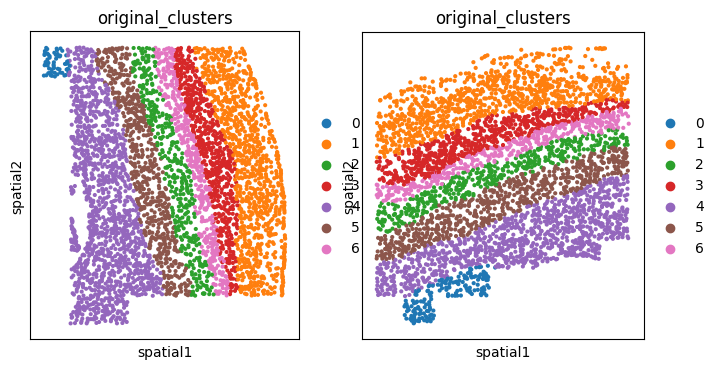

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

sc.pl.spatial(ad, color='original_clusters', spot_size=30, ax=axes[0], show=False)
sc.pl.spatial(ad_target, color='original_clusters', spot_size=30, ax=axes[1], show=False)
plt.show()

In [5]:
spatial_coords_target = ad_target.obsm['spatial']
x_target = spatial_coords_target[:, 1]
y_target = spatial_coords_target[:, 0]

# fig,ax = plt.subplots()

# rasterize at 30um resolution (assuming positions are in um units) and plot
XJ,YJ,J = STalign.rasterize(x_target,y_target,dx=20,blur=1.5, draw=False)

In [6]:
spatial_coords = ad.obsm['spatial']
x = -spatial_coords[:, 0]
y = spatial_coords[:, 1]

# rasterize at 30um resolution (assuming positions are in um units) and plot
XI,YI,I = STalign.rasterize(x,y,dx=20,blur=1.5,draw=False)

In [7]:
x_target = x_target +2000
y_target = y_target +1600

x = x -3500
y = y -700

In [8]:
# rasterize at 30um resolution (assuming positions are in um units) and plot
XI,YI,I = STalign.rasterize(x,y,dx=20,blur=1.5,draw=False)
XJ,YJ,J = STalign.rasterize(x_target,y_target,dx=20,blur=1.5,draw=False)

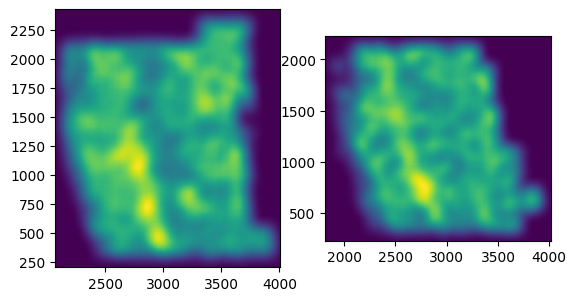

In [9]:
# get extent of images
extentI = STalign.extent_from_x((YI,XI))
extentJ = STalign.extent_from_x((YJ,XJ))

# plot rasterized images
fig,ax = plt.subplots(1,2)
ax[0].imshow(I[0], extent=extentI)
ax[1].imshow(J[0], extent=extentJ)
ax[0].invert_yaxis()
ax[1].invert_yaxis()

CPU times: user 8min 13s, sys: 19 s, total: 8min 32s
Wall time: 9min 43s


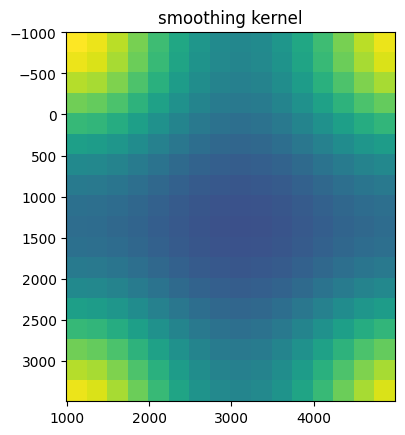

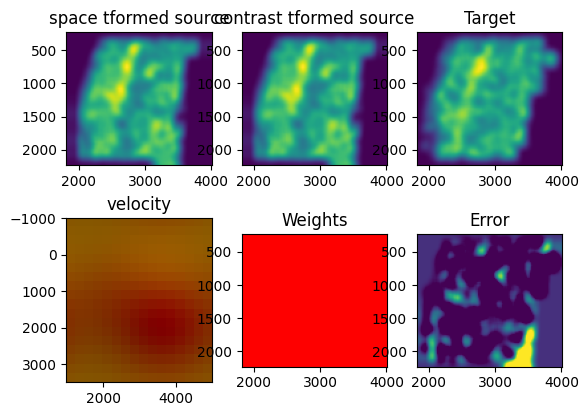

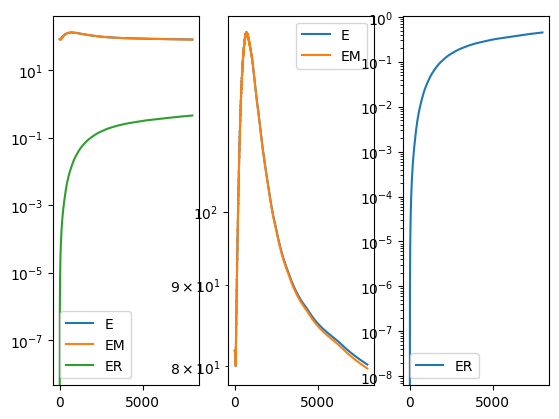

In [10]:
%%time
# run LDDMM
# specify device (default device for STalign.LDDMM is cpu)
if torch.cuda.is_available():
    device = 'cuda:0'
else:
    device = 'cpu'

# keep all other parameters default
params = {
            # 'niter':10000,
            # 'pointsI':pointsI,
            # 'pointsJ':pointsJ,
            # 'L':L,'T':T,
            'niter':8000,
            'device':device,
            'epV': 20,
            'sigmaA': 1, #standard deviation of artifact intensities
            'sigmaB': 1, #standard deviation of background intensities
            'sigmaM': 1, #standard deviation of matching tissue intenities
          }

out = STalign.LDDMM([YI,XI],I,[YJ,XJ],J,**params)

In [14]:
# get necessary output variables
A = out['A']
v = out['v']
xv = out['xv']


In [15]:
pointsI = torch.tensor(np.stack([y, x], 1), device='cuda', dtype=torch.float64)

# apply transform to original points
tpointsI= STalign.transform_points_source_to_target(xv,v,A, pointsI)

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI.is_cuda:
    tpointsI = tpointsI.cpu()

#switch from row column coordinates (y,x) to (x,y)
xI_LDDMM = tpointsI[:,1]
yI_LDDMM = tpointsI[:,0]

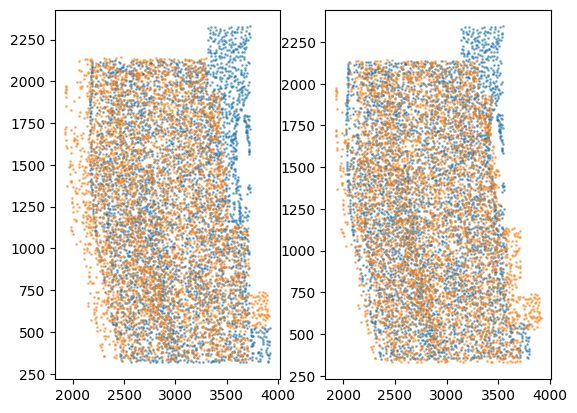

In [16]:
fig,ax = plt.subplots(1,2)
ax[0].scatter(x,y,s=1,alpha=0.5, label='source with initial affine transformation')
ax[0].scatter(x_target,y_target,s=1,alpha=0.5, label='target')
ax[1].scatter(xI_LDDMM,yI_LDDMM,s=1,alpha=0.5, label = 'source STaligned')
ax[1].scatter(x_target,y_target,s=1,alpha=0.5, label='target')
# ax[0].legend(markerscale = 10, loc = 'lower left')
# ax[1].legend(markerscale = 10, loc = 'lower left')

In [17]:
from sklearn.metrics import pairwise

f1 = np.column_stack((x_target, y_target))  # Shape: (n_points, 2)
f2 = np.column_stack((xI_LDDMM, yI_LDDMM))  # Shape: (n_points, 2)
alignment = pairwise.euclidean_distances(f1, f2)
alignment = np.exp(-alignment)

alignment_df = pd.DataFrame(alignment)


In [18]:
# Save as .pkl
alignment_df.to_pickle("31_32_AlignmentPi.pkl")

## LAA

In [19]:
def cal_layer_based_alignment_result_mHypothalamus(alignment, s1, s2):
    #fei added
    labels = []
    labels.extend(s1.obs['original_clusters'])
    labels.extend(s2.obs['original_clusters'])

    res = []
    #l_dict = {"0": 0, "1": 1, "2": 2, "3": 3, "4": 4, "5": 5, "6": 6}
    cnt0 = 0
    ir = 0
    max_smallerThan0 = []
    sum_smallerThan0 = []
    min_smallerThan0 = []

    for i, elem in enumerate(alignment):
        #if np.sum(elem)>0:
        if np.max(elem) - np.min(elem) != 0:
            if labels[i] == labels[elem.argmax() + alignment.shape[0]]:
                cnt0 += 1
        else:
            ir += 1
            max_smallerThan0.append(np.max(elem))
            sum_smallerThan0.append(np.sum(elem))
            min_smallerThan0.append(np.min(elem))
    print("the number of sum alignment equals 0:", str(cnt0))
    if len(sum_smallerThan0)>0:
        print("sum in sum alignment equals 0 is between", np.min(sum_smallerThan0), np.max(sum_smallerThan0))
        print("max in sum alignment equals 0 is between", np.min(max_smallerThan0), np.max(max_smallerThan0))
        print("min in sum alignment equals 0 is between", np.min(min_smallerThan0), np.max(min_smallerThan0))
    res.extend([cnt0])
    return res

In [20]:
res = cal_layer_based_alignment_result_mHypothalamus(alignment, ad, ad_target)
res[0]/len(ad.obs['original_clusters'])

the number of sum alignment equals 0: 736


0.1775633293124246

In [83]:
alignment.shape

(3611, 3596)

## ARI

In [21]:
from sklearn.metrics import adjusted_rand_score


def compute_alignment_ari(sliceA, sliceB, pi):
    mapped_clusters = []
    for j in range(pi.shape[1]):
        mapping = pi[:, j]
        #original: if np.sum(mapping) > 0:
        if np.max(mapping) - np.min(mapping) != 0:
            i = np.argmax(mapping)
            mapped_clusters.append(sliceA.obs['original_clusters'][i])
        else:
            mapped_clusters.append("NULL")
    assert len(sliceB.obs['original_clusters']) == len(mapped_clusters)
    true_clusters_mapped_region = []
    mapped_clusters_mapped_region = []
    for i in range(len(sliceB.obs['original_clusters'])):
        if mapped_clusters[i] != "NULL":
            true_clusters_mapped_region.append(sliceB.obs['original_clusters'][i])
            mapped_clusters_mapped_region.append(mapped_clusters[i])

    ari = adjusted_rand_score(true_clusters_mapped_region, mapped_clusters_mapped_region)
    return ari

In [22]:
ari = compute_alignment_ari(ad_target, ad, alignment)
ari

0.7920708260107665

## 3D

In [23]:
c_dict = {
    1: '#1f77b4',
    2: '#ff7f0e',
    3: '#2ca02c',
    4: '#d62728',
    5: '#9467bd',
    6: '#8c564b',
    0: '#e377c2'
    }

In [24]:
dfs = ad.obs['original_clusters']
df1 = dfs.reset_index()
df1.head()

,index,original_clusters
0,100041328926932918570941555647599217925,1
1,100066386586660919794878665136894625703,2
2,100089304247560281814261530886638382920,1
3,100130441255313654864261936530792273542,3
4,100264571106412966112945841662601175676,4


In [25]:
df3_1 = pd.DataFrame(
    {
        "X": xI_LDDMM,
        "Y": yI_LDDMM,
    },
)

results1 = pd.concat([df1, df3_1], axis=1)
results1['Z'] = 32
results1['slice'] = 'slice32'
results1

,index,original_clusters,X,Y,Z,slice
0,100041328926932918570941555647599217925,1,2157.095294,1388.636774,32,slice32
1,100066386586660919794878665136894625703,2,2855.581861,1202.672665,32,slice32
2,100089304247560281814261530886638382920,1,2028.728952,1779.928582,32,slice32
3,100130441255313654864261936530792273542,3,2513.621197,1167.625423,32,slice32
4,100264571106412966112945841662601175676,4,3285.297878,903.052317,32,slice32
...,...,...,...,...,...,...
4140,99313655668851798305862075572360852245,1,2039.450210,1595.510196,32,slice32
4141,99362714030907400558551694843706883556,1,2047.611675,2095.997006,32,slice32
4142,99434568482370616061094992947385476620,4,2946.843773,2104.729514,32,slice32
4143,99456067362493193970419180381005240507,1,2360.889670,1944.132366,32,slice32


In [27]:
results1.to_csv("32.csv", index=False)

## Plot 3D

In [ ]:
# List of filenames
filenames = [f"{i}.csv" for i in range(33)]

# Read and combine CSV files
dfs = [pd.read_csv(file) for file in filenames]
combined_df = pd.concat(dfs, ignore_index=True)

# Display the combined DataFrame
combined_df


In [ ]:
c_dict = {
    0: '#1f77b4',
    1: '#ff7f0e',
    2: '#2ca02c',
    3: '#d62728',
    4: '#9467bd',
    5: '#8c564b',
    6: '#e377c2'
    }

combined_df['celltype_colors'] = combined_df['original_clusters'].replace(c_dict)
combined_df.to_csv('STalign_merfish_aligned_coordinates_colors.csv', index=False)

In [2]:
def plot_3d(
    loc,
    val=None,
    color=None,
    figsize=(12,12),
    return_fig=True,
    elev=None,
    azim=None,
    roll=None,
    xlim=None,
    ylim=None,
    zlim=None,
    frameon=True,
    save_path=None,
    save_dpi=150,
    show=True,
    *args,
    **kwargs
):
    """Plot all slices stacked in 3D

    Plot all slices stacked with a given number of subplots rows and columns. Spots/cells colored by spatial domain.

    Args:
        loc: An array of the coordinates of each spots/cells in all slices, which the first three columns are X-axis, Y-axis, Z-axis coordinates.
        val: The colors of each spots/cells given in loc use to plot.
        color: The colors of each spots/cells given in loc use to plot.
        figsize: Size of the figure.
        return_fig: Whether to return the figure.
        elev: The elevation angle in the vertical plane in degrees. If ``None`` then the initial value as specified in the ``Axes3D`` constructor is used.
        azim: The azimuth angle in the horizontal plane in degrees. If ``None`` then the initial value as specified in the ``Axes3D`` constructor is used.
        xlim: A tuple given the left and right xlims in X-axis.
        ylim: A tuple given the left and right xlims in Y-axis.
        zlim: A tuple given the left and right xlims in Z-axis.
        frameon: Whether to hide the coordinate axes.
        save_path: A string representing the path directory where the figure saved.
        save_dpi: The resolution in dots per inch.
        show: Whether to show the figure.

    Returns:
        A ``matplotlib.figure.Figure`` object
    """
    if 'marker' not in kwargs.keys():
        kwargs['marker'] = 'o'
    if 's' not in kwargs.keys():
        kwargs['s'] = 5
    if 'cmap' not in kwargs.keys():
        kwargs['cmap'] = 'Spectral_r'
    fig = plt.figure(figsize=figsize)
    ax = fig.add_subplot(projection='3d')
    if (elev is not None) and (azim is not None) and (roll is not None):
        ax.view_init(elev, azim, roll)
    if color is None:
        ax.scatter(loc[:,0], loc[:,1], loc[:,2],c=val,*args,**kwargs)
    else:
        ax.scatter(loc[:,0], loc[:,1], loc[:,2],c=color,*args,**kwargs)
    
    if xlim is not None:
        ax.set_xlim(xlim)
    if ylim is not None:
        ax.set_ylim(ylim)
    # if zlim is not None:
    #     ax.set_zlim(zlim)
    # scale the z axis
    # z_min = loc[:, 2].min() * 0.5
    # z_max = loc[:, 2].max() * 0.5
    # ax.set_zlim(z_min, z_max)
    ax.set_box_aspect([1, 1, 2])
    # ax.set_aspect('equal')
    if not frameon:
        plt.axis('off')
        plt.grid(b=None)
    if save_path is not None:
        print(save_path)
        plt.savefig(save_path,dpi=save_dpi,bbox_inches='tight')
    if show:
        plt.show()
    else:
        plt.close()
    if return_fig:
        return fig

In [3]:
combined_df = pd.read_csv('STalign_merfish_aligned_coordinates_colors.csv')
coords = combined_df[['X', 'Y', 'Z']]

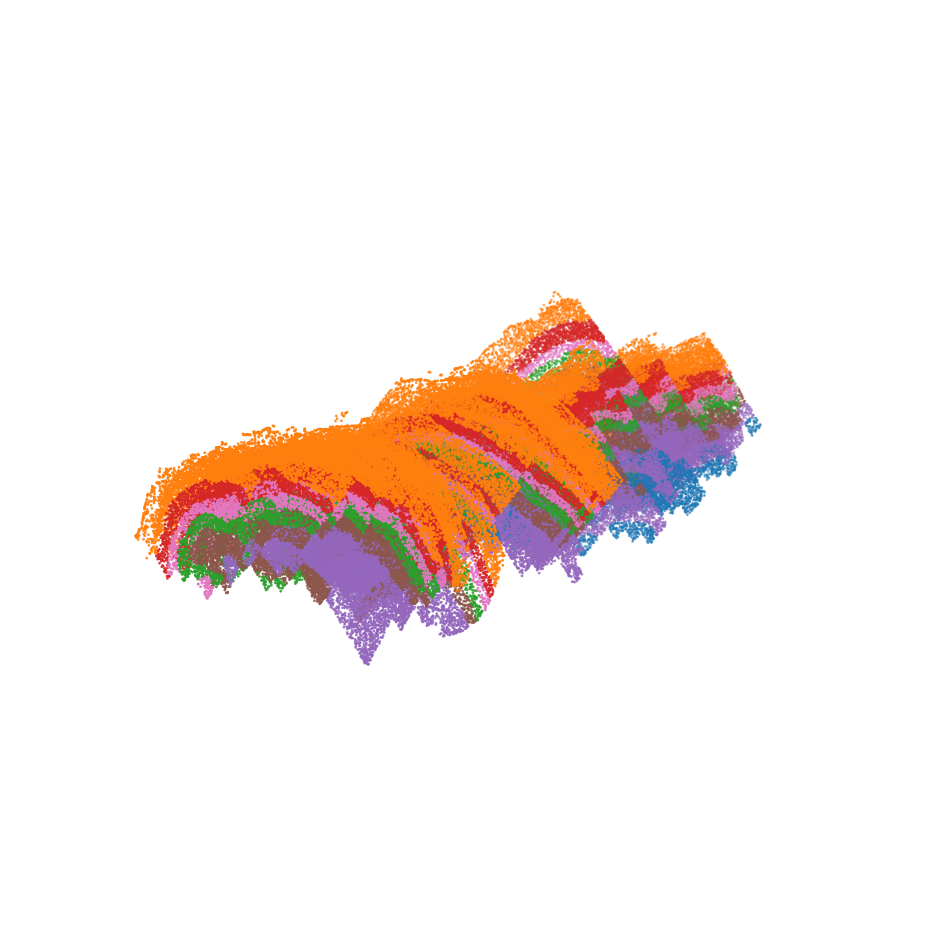

In [4]:
fig = plot_3d(coords.values, val=None, color=combined_df['celltype_colors'], elev=220, azim=120, roll =100, frameon=False, show=True, s=1, save_dpi=300, return_fig=True) # Scube is from SPACEL

fig.savefig('STalign_gtAndScube_merfish_3dviz_angle220_120_100_s=1.pdf', bbox_inches="tight")